# 01 売上と予測対象の EDA

**目的**: 予測対象の粒度、欠損・重複・ゼロ、時系列、店舗・商品の違いを把握する。全行を使用。売上は値引き後の円、test の値は予測用の仮値であり実績ではない。

学習: 2022–2024 年、予測: 2025 年。2024 年末に翌年全体を予測するため、検証は時間順に分ける。統計量は因果効果を示さない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "input").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "input").is_dir(), "プロジェクトルートまたは eda/ から実行してください"
INPUT = ROOT / "input"
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.options.display.float_format = "{:,.2f}".format
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.figsize"] = (12, 4)


In [2]:
train = pd.read_csv(INPUT / "train.csv", parse_dates=["date"])
test = pd.read_csv(INPUT / "test.csv", parse_dates=["date"])
menus = pd.read_csv(INPUT / "menus.csv")
stores = pd.read_csv(INPUT / "stores.csv")
keys = ["date", "store_id", "item_id"]
for name, df in [("train", train), ("test", test)]:
    print(f"\n{name}: shape={df.shape}, date={df.date.min().date()}〜{df.date.max().date()}, duplicates={df.duplicated(keys).sum():,}")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "unique": df.nunique()}))
    print("stores:",df.store_id.nunique(), "items:",df.item_id.nunique(), "days:",df.date.nunique(), "expected Cartesian rows:",df.date.nunique()*df.store_id.nunique()*df.item_id.nunique())
    print("sales_amount:",df.sales_amount.describe(percentiles=[.5,.9,.99]).to_dict(), "zero fraction:", (df.sales_amount==0).mean())
print("train/test key overlap:", len(train.merge(test, on=keys, how="inner")))
print("test sales_amount は予測用の初期値:",test.sales_amount.value_counts().head().to_dict())


train: shape=(920640, 4), date=2022-01-01〜2024-12-31, duplicates=0
stores: 10 items: 84 days: 1096 expected Cartesian rows: 920640
sales_amount: {'count': 920640.0, 'mean': 6794.833864485575, 'std': 11548.979592752208, 'min': 0.0, '50%': 2610.0, '90%': 20000.0, '99%': 57000.0, 'max': 148460.0} zero fraction: 0.2649374348279458

test: shape=(306600, 4), date=2025-01-01〜2025-12-31, duplicates=0
stores: 10 items: 84 days: 365 expected Cartesian rows: 306600
sales_amount: {'count': 306600.0, 'mean': 0.0, 'std': 0.0, 'min': 0.0, '50%': 0.0, '90%': 0.0, '99%': 0.0, 'max': 0.0} zero fraction: 1.0
train/test key overlap: 0
test sales_amount は予測用の初期値: {0.0: 306600}


,dtype,nulls,unique
date,datetime64[us],0,1096
store_id,str,0,10
item_id,str,0,84
sales_amount,float64,0,9484


,dtype,nulls,unique
date,datetime64[us],0,365
store_id,str,0,10
item_id,str,0,84
sales_amount,float64,0,1


## 時系列・曜日・祝日

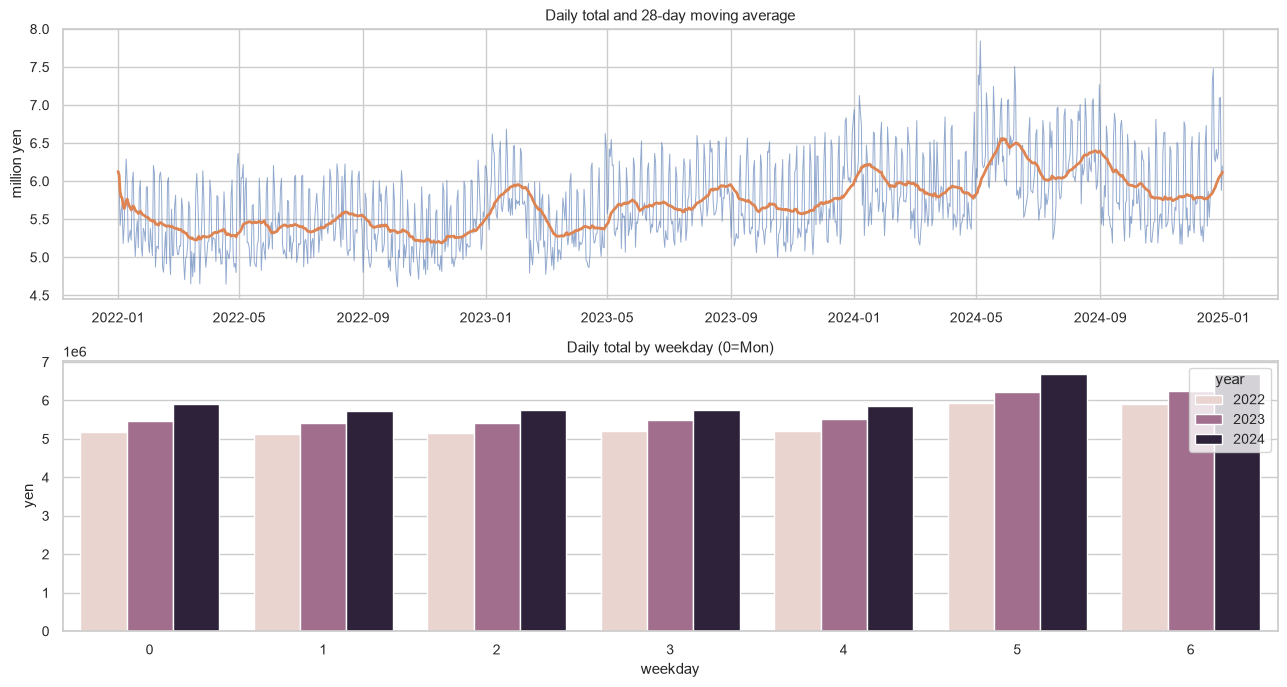

,count,sum,mean,median,std
year,,,,,
2022,365,"1,966,825,638.00","5,388,563.39","5,247,891.00","424,586.19"
2023,365,"2,074,788,900.00","5,684,353.15","5,576,538.00","474,049.84"
2024,366,"2,213,981,311.00","6,049,129.27","5,945,384.00","556,546.13"


In [3]:
daily = train.groupby("date", as_index=False).sales_amount.sum()
daily["year"] = daily.date.dt.year
daily["weekday"] = daily.date.dt.dayofweek
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(daily.date, daily.sales_amount / 1e6, lw=.7, alpha=.6)
ax[0].plot(daily.date, daily.sales_amount.rolling(28, min_periods=1).mean()/1e6, lw=2)
ax[0].set(title="Daily total and 28-day moving average", ylabel="million yen")
sns.barplot(data=daily, x="weekday", y="sales_amount", hue="year", errorbar=None, ax=ax[1]); ax[1].set(title="Daily total by weekday (0=Mon)", ylabel="yen")
plt.tight_layout(); plt.show()
display(daily.groupby("year").sales_amount.agg(["count","sum","mean","median","std"]))

count         mean       median
year weekend is_holiday                                 
2022 False   False         245 5,130,425.35 5,124,937.00
             True           15 5,925,316.00 5,983,431.00
     True    False         104 5,912,149.89 5,925,807.50
             True            1 6,128,098.00 6,128,098.00
2023 False   False         247 5,419,212.32 5,390,175.00
             True           13 6,277,967.38 6,324,090.00
     True    False         101 6,235,536.67 6,272,110.00
             True            4 6,210,169.50 6,163,063.50
2024 False   False         248 5,740,792.40 5,711,141.50
             True           14 6,770,849.57 6,729,791.50
     True    False          97 6,667,603.48 6,623,558.00
             True            7 6,959,337.57 6,797,153.00

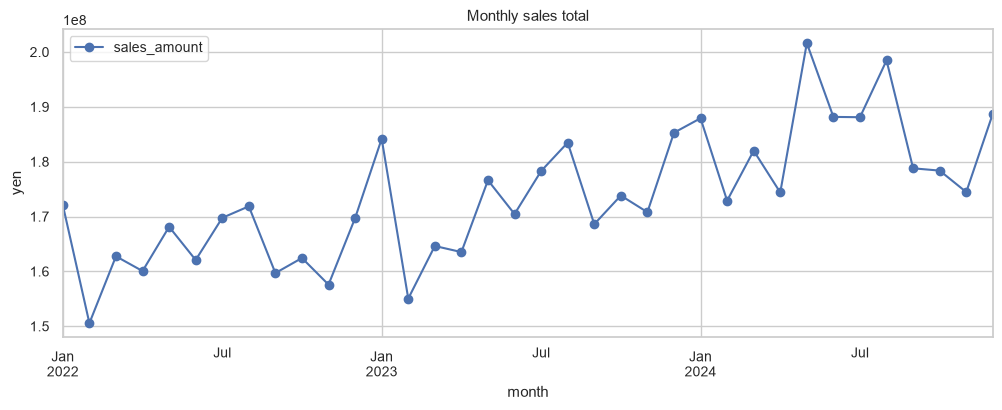

In [4]:
calendar = pd.read_csv(INPUT / "calendar.csv", parse_dates=["date"])
daily_cal = daily.merge(calendar, on="date", validate="one_to_one")
daily_cal["weekend"] = daily_cal.date.dt.dayofweek >= 5
display(daily_cal.groupby(["year", "weekend", "is_holiday"], observed=True).sales_amount.agg(["count","mean","median"]))
monthly = train.assign(month=train.date.dt.to_period("M").dt.to_timestamp()).groupby("month",as_index=False).sales_amount.sum()
monthly.plot(x="month", y="sales_amount", marker="o", title="Monthly sales total", ylabel="yen", figsize=(12,4)); plt.show()

## 店舗・商品・カテゴリ
全期間の合計は販売期間の長さを反映する。商品ごとの平均には販売停止日の 0 も含む。

,store_id,area_type,floor_area,sum,mean
3,S004,suburban_sc,358.10,"834,023,019.00","9,059.17"
9,S010,urban_core,271.90,"794,434,132.00","8,629.15"
0,S001,urban_core,323.90,"751,903,554.00","8,167.18"
2,S003,suburban_sc,429.60,"721,893,395.00","7,841.21"
1,S002,office,365.00,"638,998,882.00","6,940.81"
4,S005,roadside,363.50,"599,744,387.00","6,514.43"
6,S007,residential,282.30,"540,727,217.00","5,873.38"
7,S008,office,357.60,"506,495,573.00","5,501.56"
5,S006,residential,340.30,"436,257,469.00","4,738.63"
8,S009,roadside,306.30,"431,118,221.00","4,682.81"


,item_id,total,mean,zero_fraction,item_name,category,available_daypart,menu_type,season_code,campaign_tag
1,M002,"807,877,150.00","73,711.42",0.00,Drink Bar (With Main),drink_bar,all_day,core,NaN,NaN
16,M017,"235,509,890.00","21,488.13",0.00,Pepper Steak Plate,main,all_day,core,NaN,NaN
9,M010,"234,212,799.00","21,369.78",0.00,Stewed Beef Omelet Rice,main,all_day,core,NaN,NaN
6,M007,"225,978,870.00","20,618.51",0.00,Cheese In Hamburg,main,all_day,core,NaN,NaN
8,M009,"224,575,898.00","20,490.50",0.00,Seafood Cream Pasta,main,all_day,core,NaN,NaN
2,M003,"211,272,170.00","19,276.66",0.00,Classic Hamburg Steak,main,all_day,core,NaN,NaN
3,M004,"204,373,376.00","18,647.21",0.00,Chicken Grill Plate,main,all_day,core,NaN,NaN
7,M008,"202,981,603.00","18,520.22",0.00,Miso Butter Chicken,main,all_day,core,NaN,NaN
11,M012,"202,965,301.00","18,518.73",0.00,Gratin Doria,main,all_day,core,NaN,NaN
15,M016,"195,728,138.00","17,858.41",0.00,Avocado Taco Rice,main,all_day,core,NaN,NaN


,,items,sales,mean_zero_fraction
category,menu_type,,,
main,core,15,"2,979,284,204.00",0.00
drink_bar,core,2,"829,976,390.00",0.02
main,seasonal,8,"724,970,022.00",0.75
lunch,core,12,"621,753,434.00",0.01
side,core,12,"447,354,020.00",0.00
dessert,core,12,"254,667,323.00",0.04
kids,core,6,"209,845,470.00",0.08
main,collaboration,4,"84,900,071.00",0.95
dessert,seasonal,4,"56,277,115.00",0.75


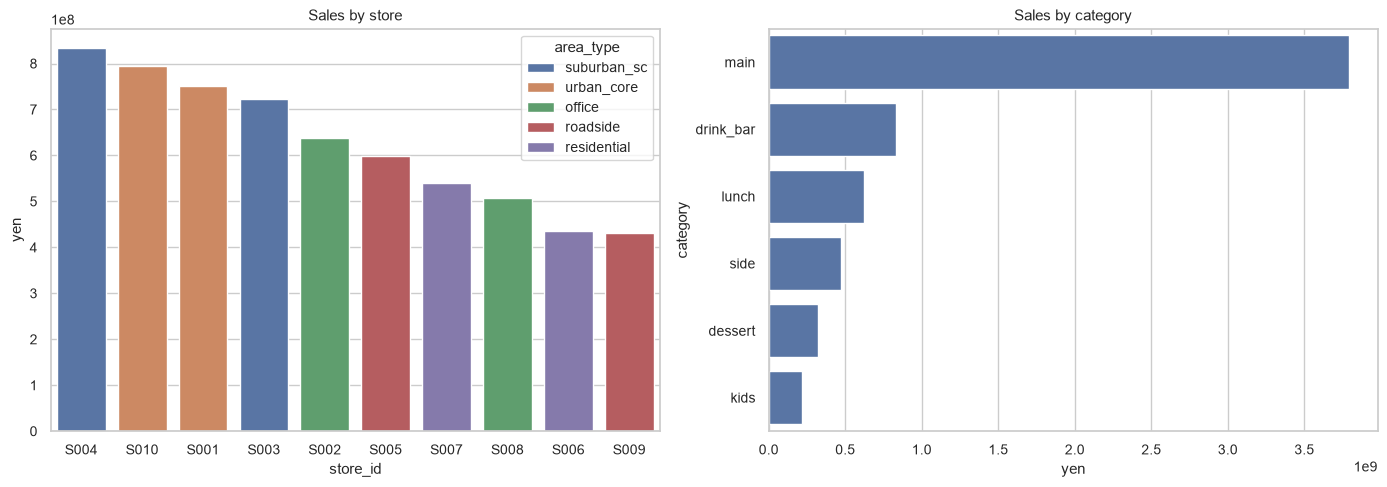

In [5]:
s = train.groupby("store_id").sales_amount.agg(["sum","mean"]).merge(stores, on="store_id", validate="one_to_one").sort_values("sum", ascending=False)
display(s[["store_id","area_type","floor_area","sum","mean"]])
item = train.groupby("item_id").sales_amount.agg(total="sum", mean="mean", zero_fraction=lambda x: (x==0).mean()).reset_index().merge(menus,on="item_id",validate="one_to_one")
display(item.sort_values("total",ascending=False).head(20))
display(item.groupby(["category","menu_type"], observed=True).agg(items=("item_id","size"),sales=("total","sum"), mean_zero_fraction=("zero_fraction","mean")).sort_values("sales",ascending=False))
fig,ax=plt.subplots(1,2,figsize=(14,5)); sns.barplot(data=s,x="store_id",y="sum",hue="area_type",dodge=False,ax=ax[0]); ax[0].set(title="Sales by store",ylabel="yen"); sns.barplot(data=item.groupby("category",as_index=False).total.sum().sort_values("total",ascending=False),x="total",y="category",ax=ax[1]); ax[1].set(title="Sales by category",xlabel="yen"); plt.tight_layout(); plt.show()

## ゼロ売上と分布の変化

Negative sales rows: 0


rows  zero_fraction     mean   median
year menu_type                                             
2022 collaboration   43800           0.95   651.90     0.00
     core           215350           0.02 7,847.05 3,840.00
     seasonal        47450           0.75 5,235.21     0.00
2023 collaboration   43800           0.95   845.68     0.00
     core           215350           0.02 8,238.08 4,000.00
     seasonal        47450           0.75 5,556.97     0.00
2024 collaboration   43920           0.94 1,072.20     0.00
     core           215940           0.02 8,701.25 4,130.00
     seasonal        47580           0.75 6,051.74     0.00

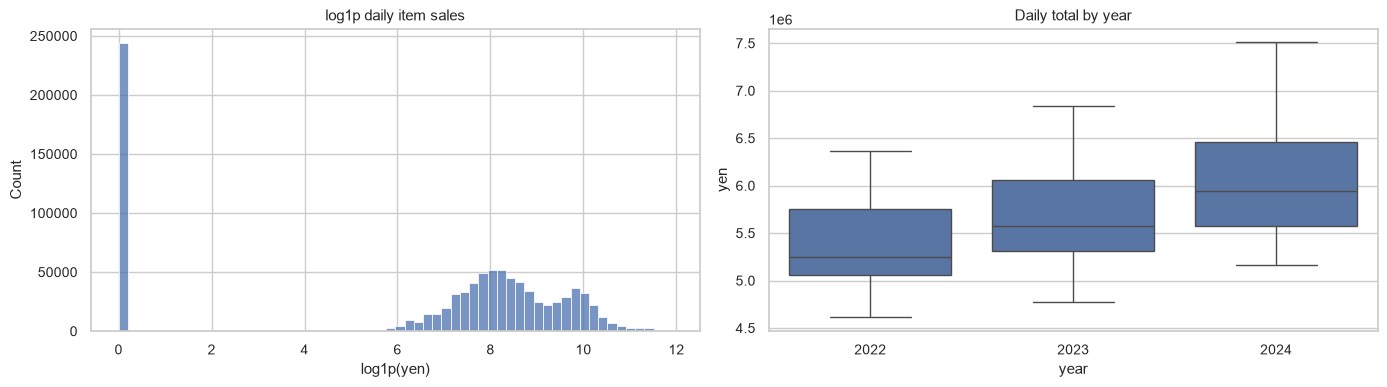

In [6]:
train_m = train.merge(menus[["item_id","menu_type","category"]], on="item_id", validate="many_to_one")
train_m["year"] = train_m.date.dt.year
summary = train_m.groupby(["year","menu_type"],observed=True).agg(rows=("sales_amount","size"),zero_fraction=("sales_amount",lambda x:(x==0).mean()), mean=("sales_amount","mean"), median=("sales_amount","median"))
display(summary)
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.histplot(np.log1p(train.sales_amount),bins=60,ax=ax[0]); ax[0].set(title="log1p daily item sales",xlabel="log1p(yen)"); sns.boxplot(data=daily,x="year",y="sales_amount",ax=ax[1],showfliers=False); ax[1].set(title="Daily total by year",ylabel="yen"); plt.tight_layout();plt.show()
print("Negative sales rows:", int((train.sales_amount < 0).sum()))

## 次の検討
- 年ごとの水準変化や価格改定を考慮し、2024 年など直近期間を検証に使う。
- 売上ゼロには販売期間外と販売中の売れ残りが混在する。`02` で販売期間を照合する。
- 公式評価は日・月と店舗・商品を組み合わせた 6 粒度。日次行 RMSE だけで最適化の良否を判断しない。